In [5]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nFIGURE_DIR:")
print(FIGURE_DIR)

print("\nResolved FIGURE_DIR:")
print(FIGURE_DIR.resolve())

Current working directory:
c:\Users\ngtht\football-prediction\notebooks\EDA

FIGURE_DIR:
..\..\results\figures\eda\eda_01_player_data

Resolved FIGURE_DIR:
C:\Users\ngtht\football-prediction\results\figures\eda\eda_01_player_data


In [6]:
#Setup 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from pathlib import Path
FIGURE_DIR = Path('../../results/figures/eda/eda_01_player_data')
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Load Group 1 files
appearances       = pd.read_csv('../../data/raw/appearances.csv')
players           = pd.read_csv('../../data/raw/players.csv')
player_valuations = pd.read_csv('../../data/raw/player_valuations.csv')

print(" Group 1 — Player Data loaded!")
print(f"  appearances       : {appearances.shape}")
print(f"  players           : {players.shape}")
print(f"  player_valuations : {player_valuations.shape}")

 Group 1 — Player Data loaded!
  appearances       : (1884051, 13)
  players           : (47669, 26)
  player_valuations : (640176, 6)


In [7]:
# Overview of all 3 files
group1 = {
    'appearances'       : appearances,
    'players'           : players,
    'player_valuations' : player_valuations
}

print(f"{'File':<25} {'Rows':>10} {'Cols':>6} {'Missing':>10} {'Missing %':>10} {'Memory':>10}")
print("-" * 75)

for name, df in group1.items():
    rows        = df.shape[0]
    cols        = df.shape[1]
    missing     = df.isnull().sum().sum()
    missing_pct = round(missing / (rows * cols) * 100, 2)
    memory      = df.memory_usage().sum() / 1024**2
    print(f"{name:<25} {rows:>10,} {cols:>6} {missing:>10,} {missing_pct:>9.2f}% {memory:>9.1f}MB")

File                            Rows   Cols    Missing  Missing %     Memory
---------------------------------------------------------------------------
appearances                1,884,051     13          2      0.00%     259.5MB
players                       47,669     26    183,816     14.83%      23.0MB
player_valuations            640,176      6     90,678      2.36%      45.9MB


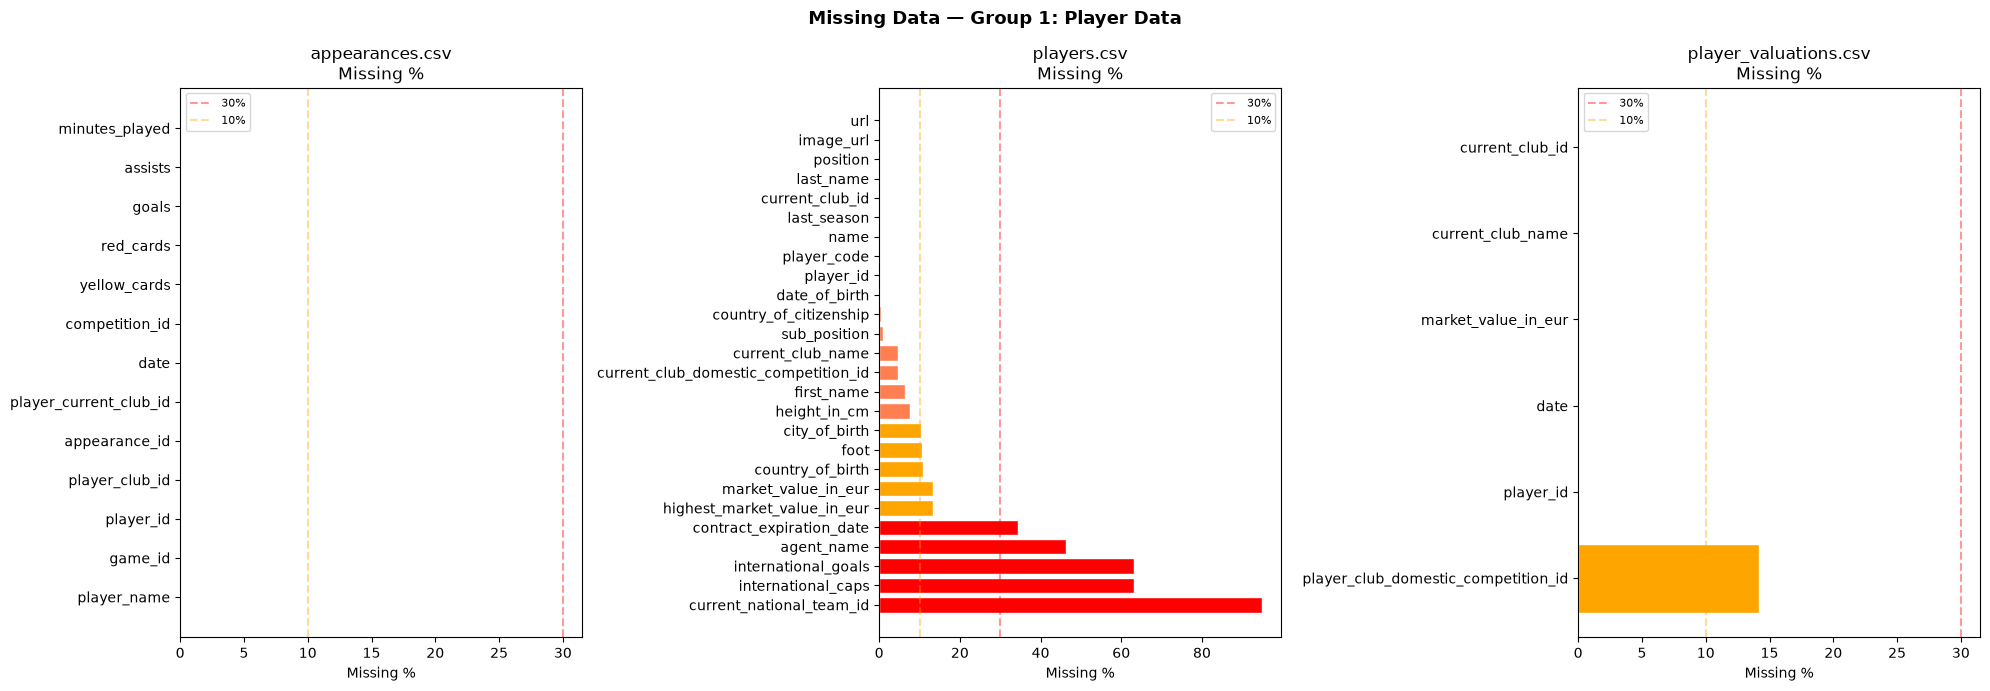

 Saved


In [8]:
# Missing Visualization: All 3 files

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

files_info = [
    (appearances,       'appearances.csv',       'steelblue'),
    (players,           'players.csv',           'coral'),
    (player_valuations, 'player_valuations.csv', 'mediumseagreen')
]

for ax, (df_f, name, color) in zip(axes, files_info):
    pct = (df_f.isnull().sum() / len(df_f) * 100).sort_values(ascending=False)
    bar_colors = ['red' if p > 30 else 'orange' if p > 10 else color
                  for p in pct.values]
    ax.barh(pct.index, pct.values, color=bar_colors, edgecolor='white')
    ax.set_title(f'{name}\nMissing %')
    ax.set_xlabel('Missing %')
    ax.axvline(30, color='red',    linestyle='--', alpha=0.4, label='30%')
    ax.axvline(10, color='orange', linestyle='--', alpha=0.4, label='10%')
    ax.legend(fontsize=8)

plt.suptitle('Missing Data — Group 1: Player Data',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_group1_missing_data_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print(" Saved")

# appearances.csv -> no missing value were detected across all variables (0%).

# player.csv -> most variables have low missing rate (<10%) agent_name, international_goals, 
# international_caps, and especially current_national_team_id (>90%)contain substantial missing values and 
# may require imputation or removal before analysis.

# player_valuation.csv -> this dataset has very few missing values. Only player_club_domestic_competition_id (~15%) 
# shows a moderate missing rate, while all other variables are complete.

In [9]:
# Unique Data Check: appearances.csv

print("=" * 60)
print("UNIQUE DATA CHECK — appearances.csv")
print("=" * 60)
print(f"Shape: {appearances.shape}")
print(f"Purpose: Match-level performance stats per player\n")

for col in appearances.columns:
    n_unique   = appearances[col].nunique()
    null_count = appearances[col].isnull().sum()
    dtype      = appearances[col].dtype

    if n_unique <= 15:
        values = appearances[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = appearances[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

        # 

UNIQUE DATA CHECK — appearances.csv
Shape: (1884051, 13)
Purpose: Match-level performance stats per player

appearance_id
  dtype=str | unique=1,884,051 | null=0
  Top 5: {'2231978_38004': 1, '2233748_79232': 1, '2234413_42792': 1, '2234418_73333': 1, '2234421_122011': 1}

game_id
  dtype=int64 | unique=73,194 | null=0
  Top 5: {4646174: 37, 2884392: 36, 4368759: 36, 4368874: 36, 4098010: 35}

player_id
  dtype=int64 | unique=28,713 | null=0
  Top 5: {38253: 664, 125781: 634, 74229: 627, 59561: 615, 55735: 592}

player_club_id
  dtype=int64 | unique=1,178 | null=0
  Top 5: {418: 11441, 131: 11355, 368: 10829, 506: 10661, 281: 10661}

player_current_club_id
  dtype=int64 | unique=1,085 | null=0
  Top 5: {589: 10218, 6890: 10170, 150: 9644, 141: 9495, 1091: 9451}

date
  dtype=str | unique=4,085 | null=0
  Top 5: {'2025-11-09': 1850, '2026-05-17': 1826, '2020-10-04': 1795, '2025-10-05': 1752, '2022-11-13': 1747}

player_name
  dtype=str | unique=28,112 | null=2
  Top 5: {'Danilo': 1176, 

In [10]:
# Unique Data Check: players.csv

print("=" * 60)
print("UNIQUE DATA CHECK — players.csv")
print("=" * 60)
print(f"Shape: {players.shape}")
print(f"Purpose: Player profile + current market value (TARGET)\n")

for col in players.columns:
    n_unique   = players[col].nunique()
    null_count = players[col].isnull().sum()
    dtype      = players[col].dtype

    if n_unique <= 15:
        values = players[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = players[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

# total : 47669
# uni : 206
# null : 6335

# ->  47,669 - 6,335 = 41,334 valueable players -> among those 41,334 players, only 206 different price points are used.

UNIQUE DATA CHECK — players.csv
Shape: (47669, 26)
Purpose: Player profile + current market value (TARGET)

player_id
  dtype=int64 | unique=47,669 | null=0
  Top 5: {10: 1, 26: 1, 65: 1, 77: 1, 80: 1}

first_name
  dtype=str | unique=10,240 | null=3090
  Top 5: {'David': 325, 'Daniel': 231, 'Lucas': 201, 'Ivan': 190, 'Kevin': 169}

last_name
  dtype=str | unique=32,440 | null=0
  Top 5: {'Kim': 138, 'Rodríguez': 103, 'García': 102, 'Lee': 102, 'González': 97}

name
  dtype=str | unique=46,413 | null=0
  Top 5: {'Paulinho': 13, 'João Pedro': 12, 'Eduardo': 10, 'Bruninho': 10, 'Vitinho': 10}

last_season
  dtype=int64 | unique=14 | null=0
  Values: [2015, 2017, 2012, 2013, 2014, 2016, 2019, 2018, 2022, 2025, 2021, 2024, 2020, 2023]

current_club_id
  dtype=int64 | unique=1,678 | null=0
  Top 5: {2553: 196, 511: 182, 987: 182, 2759: 176, 589: 174}

player_code
  dtype=str | unique=46,333 | null=0
  Top 5: {'paulinho': 13, 'joao-pedro': 12, 'eduardo': 10, 'bruninho': 10, 'vitinho': 10}

c

In [11]:
# Unique Data Check: player_valuations.csv

print("=" * 60)
print("UNIQUE DATA CHECK — player_valuations.csv")
print("=" * 60)
print(f"Shape: {player_valuations.shape}")
print(f"Purpose: Historical market value timeline per player\n")

for col in player_valuations.columns:
    n_unique   = player_valuations[col].nunique()
    null_count = player_valuations[col].isnull().sum()
    dtype      = player_valuations[col].dtype

    if n_unique <= 15:
        values = player_valuations[col].unique().tolist()
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique} | null={null_count}")
        print(f"  Values: {values}\n")
    else:
        top5 = player_valuations[col].value_counts().head(5)
        print(f"{col}")
        print(f"  dtype={dtype} | unique={n_unique:,} | null={null_count}")
        print(f"  Top 5: {top5.to_dict()}\n")

UNIQUE DATA CHECK — player_valuations.csv
Shape: (640176, 6)
Purpose: Historical market value timeline per player

player_id
  dtype=int64 | unique=41,334 | null=0
  Top 5: {39333: 57, 44162: 55, 35047: 52, 39153: 52, 51894: 52}

date
  dtype=str | unique=5,728 | null=0
  Top 5: {'2020-04-08': 12110, '2015-07-01': 4207, '2016-07-15': 2979, '2023-12-19': 1948, '2020-12-29': 1838}

market_value_in_eur
  dtype=int64 | unique=426 | null=0
  Top 5: {300000: 35956, 200000: 35699, 100000: 35154, 50000: 31996, 500000: 31487}

current_club_name
  dtype=str | unique=8,030 | null=0
  Top 5: {'Without Club': 4372, 'Unknown': 3199, 'Trabzonspor': 1464, 'Galatasaray': 1450, 'Fenerbahce': 1429}

current_club_id
  dtype=int64 | unique=5,398 | null=0
  Top 5: {800: 2418, 252: 2351, 589: 2320, 126: 2303, 2672: 2277}

player_club_domestic_competition_id
  dtype=str | unique=32 | null=90678
  Top 5: {'IT1': 49985, 'TR1': 47192, 'ES1': 37081, 'L1': 36608, 'FR1': 33259}



In [12]:
# appearances.csv : Basic info

print("=" * 60)
print("FILE 1: appearances.csv")
print("=" * 60)
print(f"Purpose : Match-level performance stats per player")
print(f"Shape   : {appearances.shape}")
print(f"\nColumn types:")
print(appearances.dtypes)
print(f"\nFirst 5 rows:")
appearances.head()

FILE 1: appearances.csv
Purpose : Match-level performance stats per player
Shape   : (1884051, 13)

Column types:
appearance_id               str
game_id                   int64
player_id                 int64
player_club_id            int64
player_current_club_id    int64
date                        str
player_name                 str
competition_id              str
yellow_cards              int64
red_cards                 int64
goals                     int64
assists                   int64
minutes_played            int64
dtype: object

First 5 rows:


,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,2234418_73333,2234418,73333,1274,76,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90


In [13]:
# add df. check unique value for each 

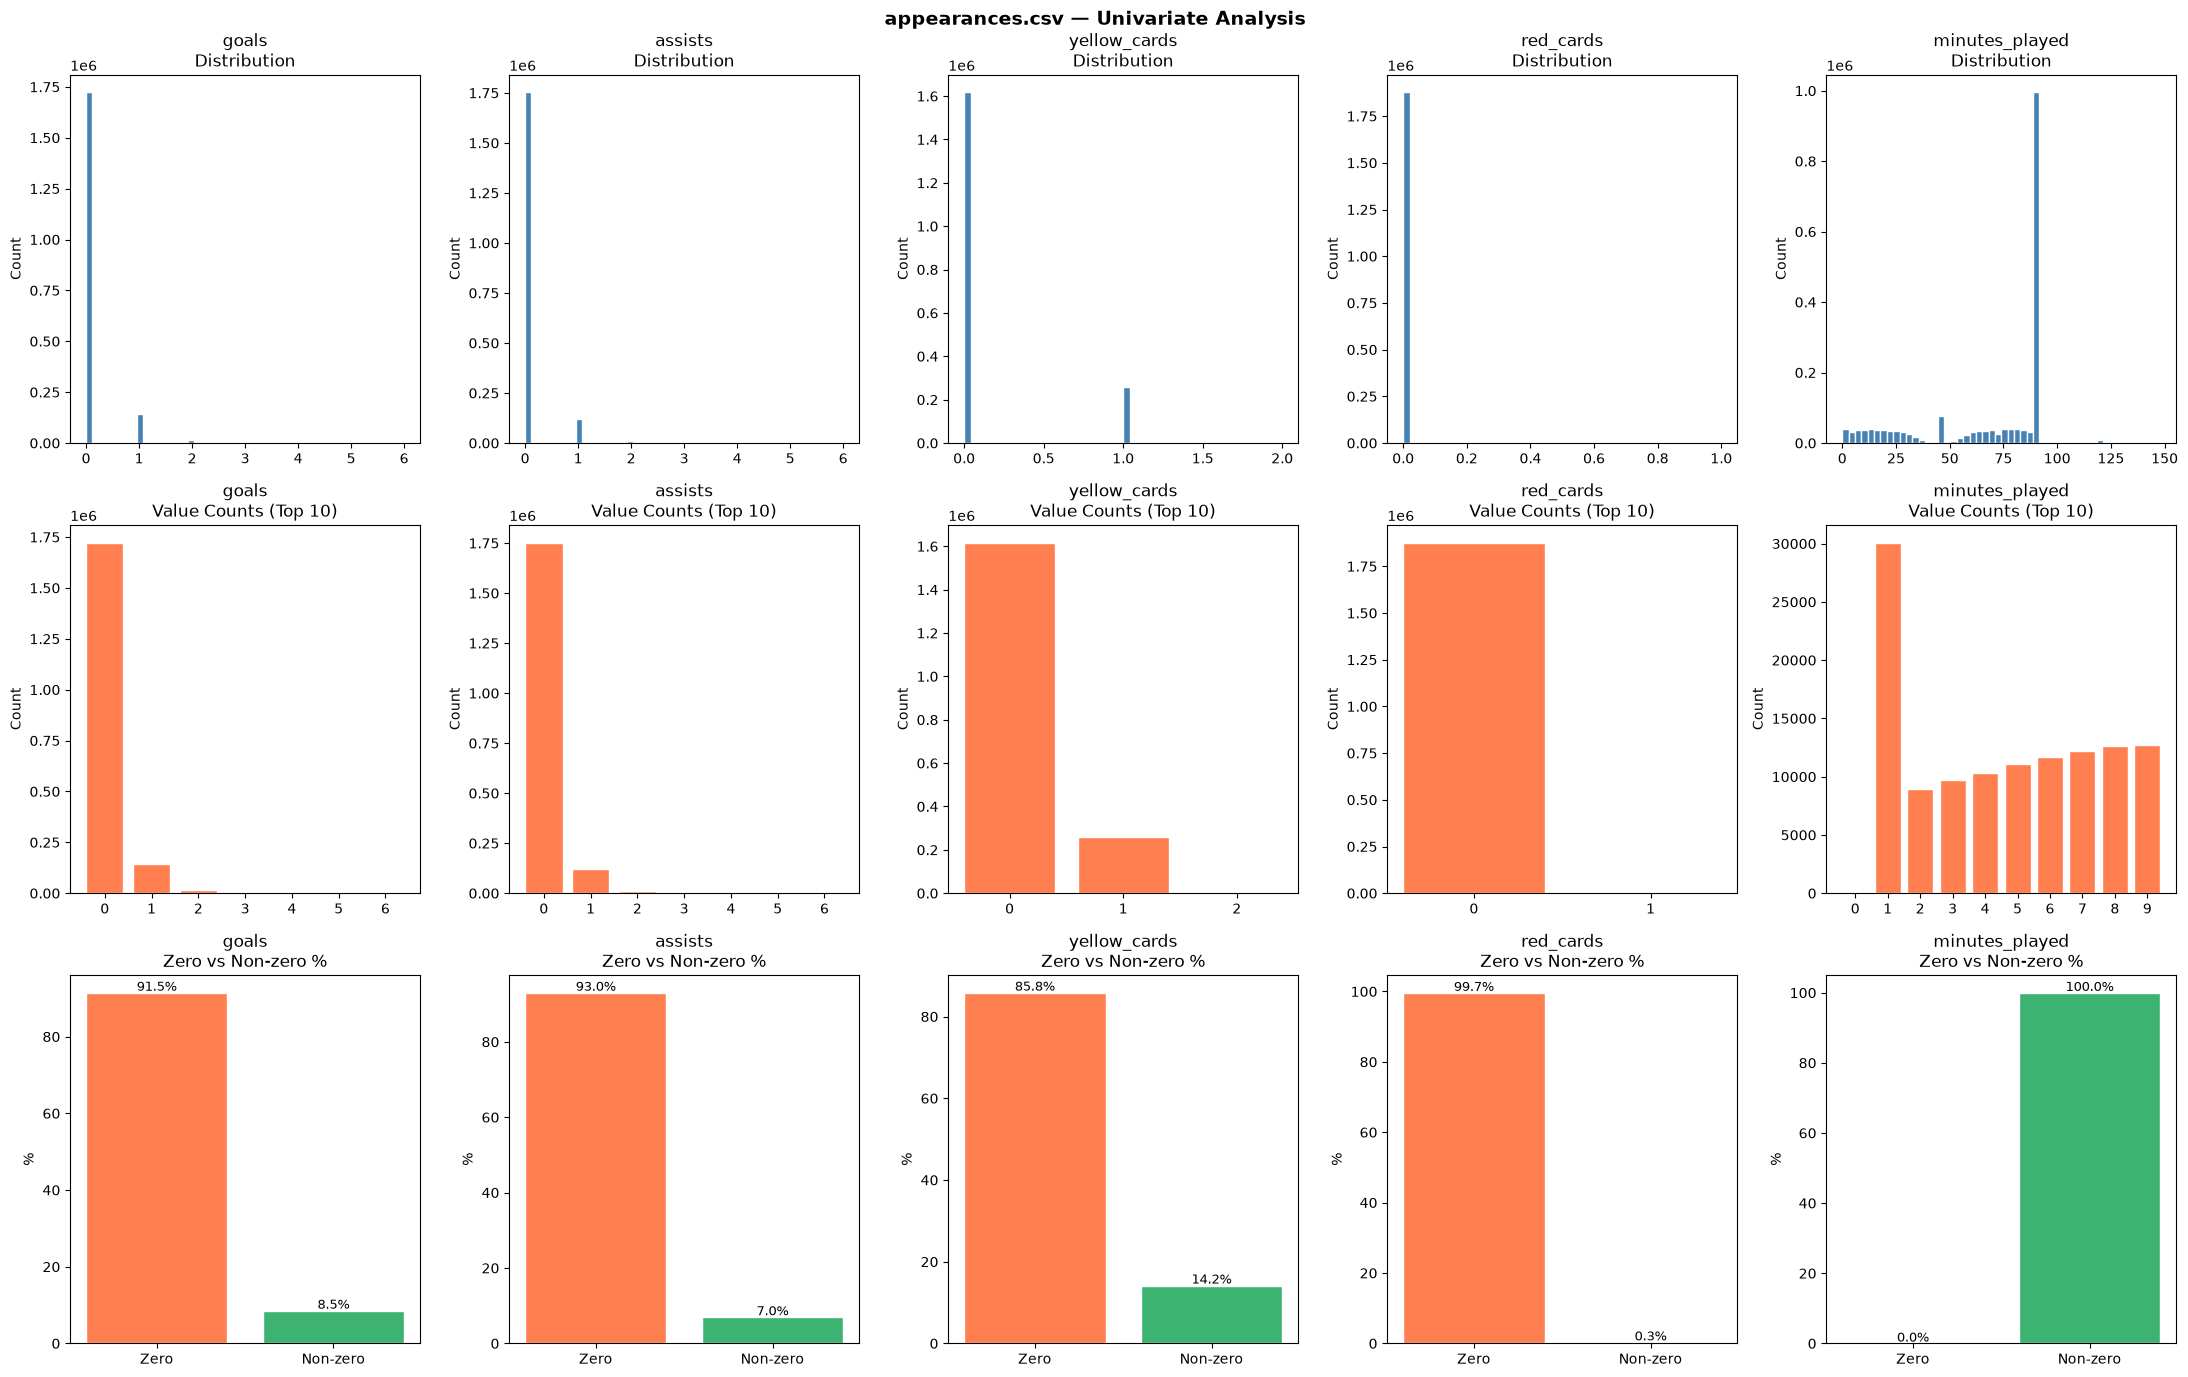

Saved


In [14]:
numerical_app = ['goals', 'assists', 'yellow_cards',
                 'red_cards', 'minutes_played']

fig, axes = plt.subplots(3, len(numerical_app), figsize=(22, 14))

for i, col in enumerate(numerical_app):
    # Row 1 — Distribution histogram
    axes[0, i].hist(appearances[col], bins=50,
                    color='steelblue', edgecolor='white')
    axes[0, i].set_title(f'{col}\nDistribution')
    axes[0, i].set_ylabel('Count')

    # Row 2 — Value counts bar chart (thay boxplot)
    val_counts = appearances[col].value_counts().sort_index().head(10)
    axes[1, i].bar(val_counts.index.astype(str), val_counts.values,
                   color='coral', edgecolor='white')
    axes[1, i].set_title(f'{col}\nValue Counts (Top 10)')
    axes[1, i].set_ylabel('Count')
    axes[1, i].tick_params(axis='x', rotation=0)

    # Row 3 — Zero vs Non-zero %
    zero    = (appearances[col] == 0).sum() / len(appearances) * 100
    nonzero = 100 - zero
    axes[2, i].bar(['Zero', 'Non-zero'], [zero, nonzero],
                   color=['coral', 'mediumseagreen'], edgecolor='white')
    axes[2, i].set_title(f'{col}\nZero vs Non-zero %')
    axes[2, i].set_ylabel('%')
    for j, v in enumerate([zero, nonzero]):
        axes[2, i].text(j, v + 0.5, f'{v:.1f}%', ha='center', fontsize=9)

plt.suptitle('appearances.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '02_appearances_univariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

# Most performance variables (goals, assists, yellow_cards, and red_cards) are zero-inflated, indicating that 
# most player appearances recorded no goals, assists, or cards.
#  minutes_played shows a strong concentration around 90 minutes, representing full-match participation.

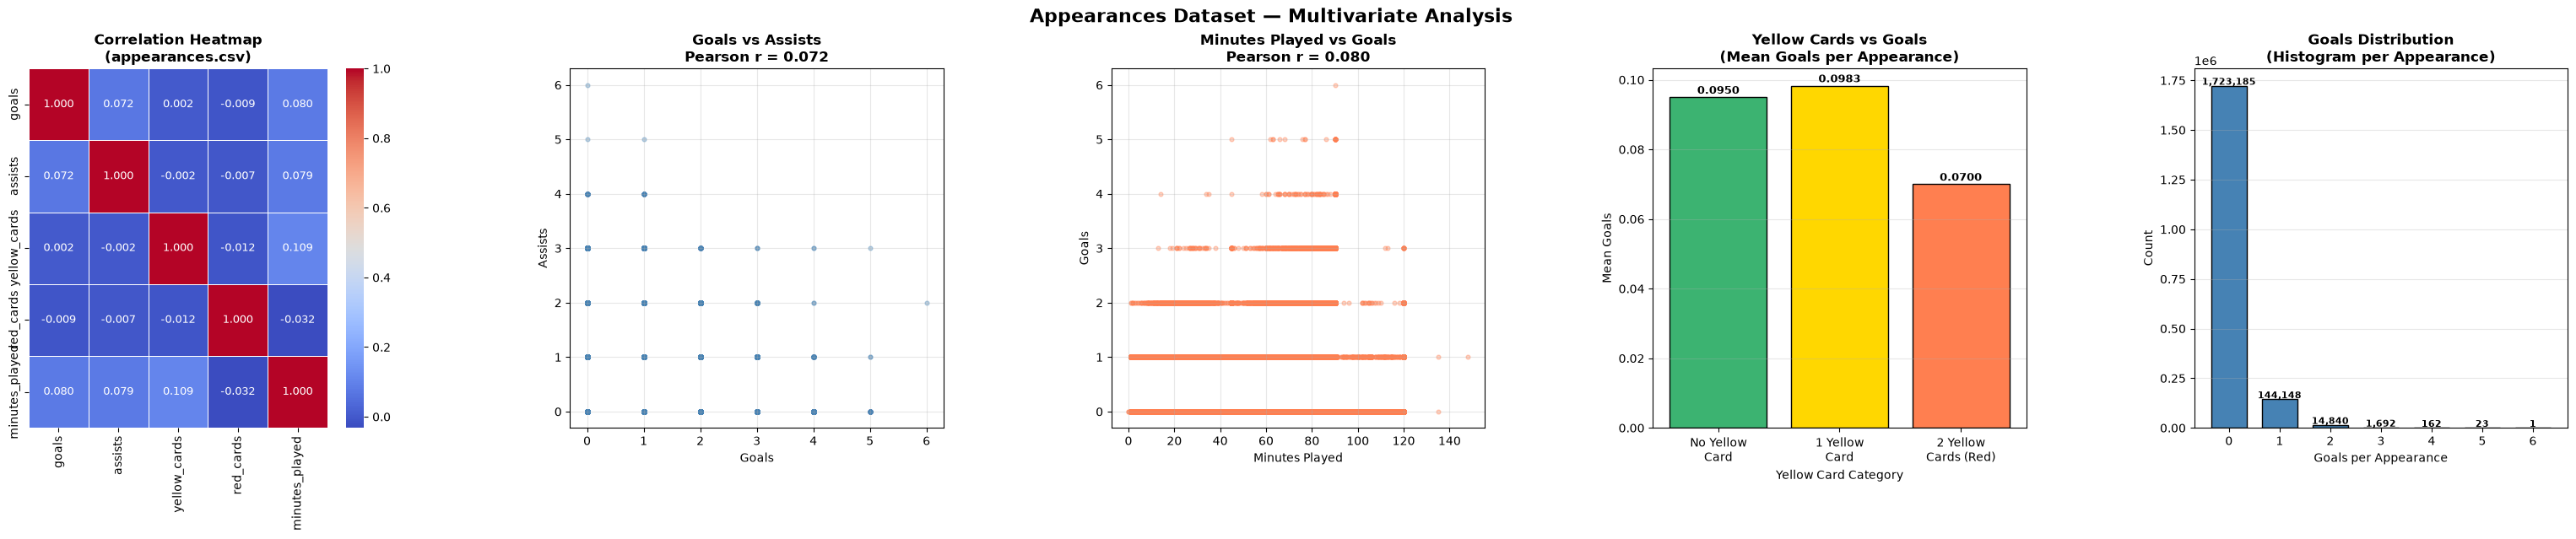

Saved


In [15]:
# appearances.csv: Multivariate

fig, axes = plt.subplots(1, 5, figsize=(32, 6))

# =====================================================
# Chart 1 — Correlation Heatmap (thay bar chart)
# =====================================================
corr_matrix = appearances[numerical_app].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    linewidths=0.5,
    ax=axes[0],
    annot_kws={'size': 9}
)
axes[0].set_title('Correlation Heatmap\n(appearances.csv)',
                  fontsize=12, fontweight='bold')

# =====================================================
# Chart 2 — Goals vs Assists
# =====================================================
corr_ga = appearances['goals'].corr(appearances['assists'])

axes[1].scatter(appearances['goals'], appearances['assists'],
                alpha=0.35, s=12, color='steelblue')
axes[1].set_title(f'Goals vs Assists\nPearson r = {corr_ga:.3f}',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Goals')
axes[1].set_ylabel('Assists')
axes[1].grid(alpha=0.3)

# =====================================================
# Chart 3 — Minutes Played vs Goals
# =====================================================
corr_mg = appearances['minutes_played'].corr(appearances['goals'])

axes[2].scatter(appearances['minutes_played'], appearances['goals'],
                alpha=0.35, s=12, color='coral')
axes[2].set_title(f'Minutes Played vs Goals\nPearson r = {corr_mg:.3f}',
                  fontsize=12, fontweight='bold')
axes[2].set_xlabel('Minutes Played')
axes[2].set_ylabel('Goals')
axes[2].grid(alpha=0.3)

# =====================================================
# Chart 4 — Yellow Cards vs Goals (Bar chart — Thống kê)
# =====================================================
yellow_goals = appearances.groupby('yellow_cards')['goals']\
                           .mean().reset_index()
yellow_goals = yellow_goals[yellow_goals['yellow_cards'] <= 2]
yellow_goals['label'] = yellow_goals['yellow_cards'].map({
    0: 'No Yellow\nCard',
    1: '1 Yellow\nCard',
    2: '2 Yellow\nCards (Red)'
})

axes[3].bar(yellow_goals['label'], yellow_goals['goals'],
            color=['mediumseagreen', 'gold', 'coral'],
            edgecolor='black')
axes[3].set_title('Yellow Cards vs Goals\n(Mean Goals per Appearance)',
                  fontsize=12, fontweight='bold')
axes[3].set_xlabel('Yellow Card Category')
axes[3].set_ylabel('Mean Goals')
axes[3].grid(axis='y', alpha=0.3)
for i, v in enumerate(yellow_goals['goals']):
    axes[3].text(i, v + 0.001, f'{v:.4f}',
                 ha='center', fontsize=9, fontweight='bold')

# =====================================================
# Chart 5 — Goals Distribution (Histogram — Phân phối)
# =====================================================
axes[4].hist(appearances['goals'], bins=range(0, 8),
             color='steelblue', edgecolor='black',
             align='left', rwidth=0.7)
axes[4].set_title('Goals Distribution\n(Histogram per Appearance)',
                  fontsize=12, fontweight='bold')
axes[4].set_xlabel('Goals per Appearance')
axes[4].set_ylabel('Count')
axes[4].set_xticks(range(0, 7))
axes[4].grid(axis='y', alpha=0.3)

for patch in axes[4].patches:
    h = patch.get_height()
    if h > 0:
        axes[4].text(patch.get_x() + patch.get_width()/2,
                     h + 5000, f'{int(h):,}',
                     ha='center', fontsize=8, fontweight='bold')

# =====================================================
plt.suptitle('Appearances Dataset — Multivariate Analysis',
             fontsize=16, fontweight='bold')
plt.subplots_adjust(left=0.04, right=0.98,
                    bottom=0.15, top=0.86, wspace=0.45)
plt.savefig(FIGURE_DIR / '03_appearances_multivariate_analysis.png',
            dpi=200, bbox_inches='tight')
plt.show()
print("Saved")

# Pearson correlation analysis shows that all variables have very weak correlations with goals (|r| < 0.10).
#  Minutes played (r = 0.080) and assists (r = 0.072) exhibit only slight positive relationships, 
# while yellow cards (r = 0.002) and red cards (r = -0.009) show virtually no correlation.

# The scatter plot confirms a very weak positive relationship between goals and assists (r = 0.072). 
# Most appearances record zero goals and zero assists,
#  indicating that scoring and assisting are largely independent at the appearance level.

# Minutes played has a very weak positive correlation with goals (r = 0.080). Although players with more playing time have a 
# slightly higher chance of scoring, playing time alone is not a strong predictor of goals.

# Back to Heat map / Yellow card so sanh voi Goals , show phan phoi  ( Thong ke - > Bar chart , Phan phoi -> Histogram)

FILE 2: players.csv
Purpose : Player profile + current market value (TARGET)
Shape   : (47669, 26)


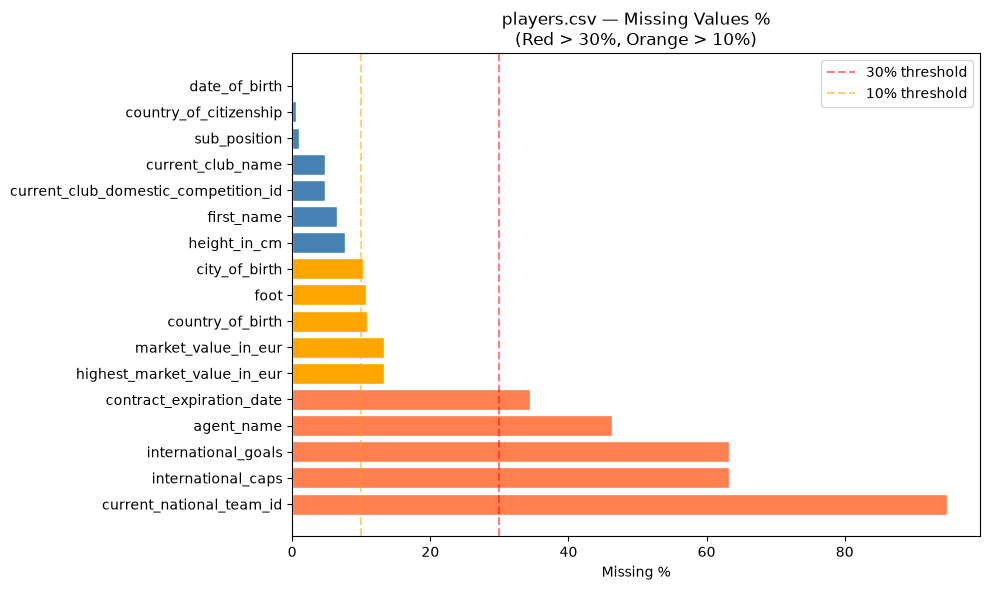


Missing Values Detail:
                                      count  percent
current_national_team_id              45211    94.84
international_caps                    30129    63.20
international_goals                   30129    63.20
agent_name                            22056    46.27
contract_expiration_date              16386    34.37
highest_market_value_in_eur            6335    13.29
market_value_in_eur                    6335    13.29
country_of_birth                       5164    10.83
foot                                   5099    10.70
city_of_birth                          4888    10.25
height_in_cm                           3666     7.69
first_name                             3090     6.48
current_club_domestic_competition_id   2272     4.77
current_club_name                      2272     4.77
sub_position                            462     0.97
country_of_citizenship                  273     0.57
date_of_birth                            49     0.10


In [16]:
# players.csv: Basic Info + Missing

print("=" * 60)
print("FILE 2: players.csv")
print("=" * 60)
print(f"Purpose : Player profile + current market value (TARGET)")
print(f"Shape   : {players.shape}")

# Missing values analysis
missing = pd.DataFrame({
    'count'  : players.isnull().sum(),
    'percent': (players.isnull().sum() / len(players) * 100).round(2)
}).sort_values('percent', ascending=False)

missing_only = missing[missing['count'] > 0]

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['coral' if p > 30 else 'orange' if p > 10 else 'steelblue' 
          for p in missing_only['percent']]
ax.barh(missing_only.index, missing_only['percent'], 
        color=colors, edgecolor='white')
ax.set_title('players.csv — Missing Values %\n(Red > 30%, Orange > 10%)')
ax.set_xlabel('Missing %')
ax.axvline(30, color='red', linestyle='--', alpha=0.5, label='30% threshold')
ax.axvline(10, color='orange', linestyle='--', alpha=0.5, label='10% threshold')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '04_players_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nMissing Values Detail:")
print(missing_only.to_string())

# Most variables have low missing rate (<10%), indicating good overall data quality. Moderate missing value (10-15%) are observed in 
# variable such as market_value_in_eur and highest_market_value_in_eur. which can be handled through imputation. Variables including 
# contract_expiration_date, agent_name, international_caps, international_goals, and current_national_team_id have high missing rates (>30%),
# largely because many players have not represented their national teams or the information is unavailable.

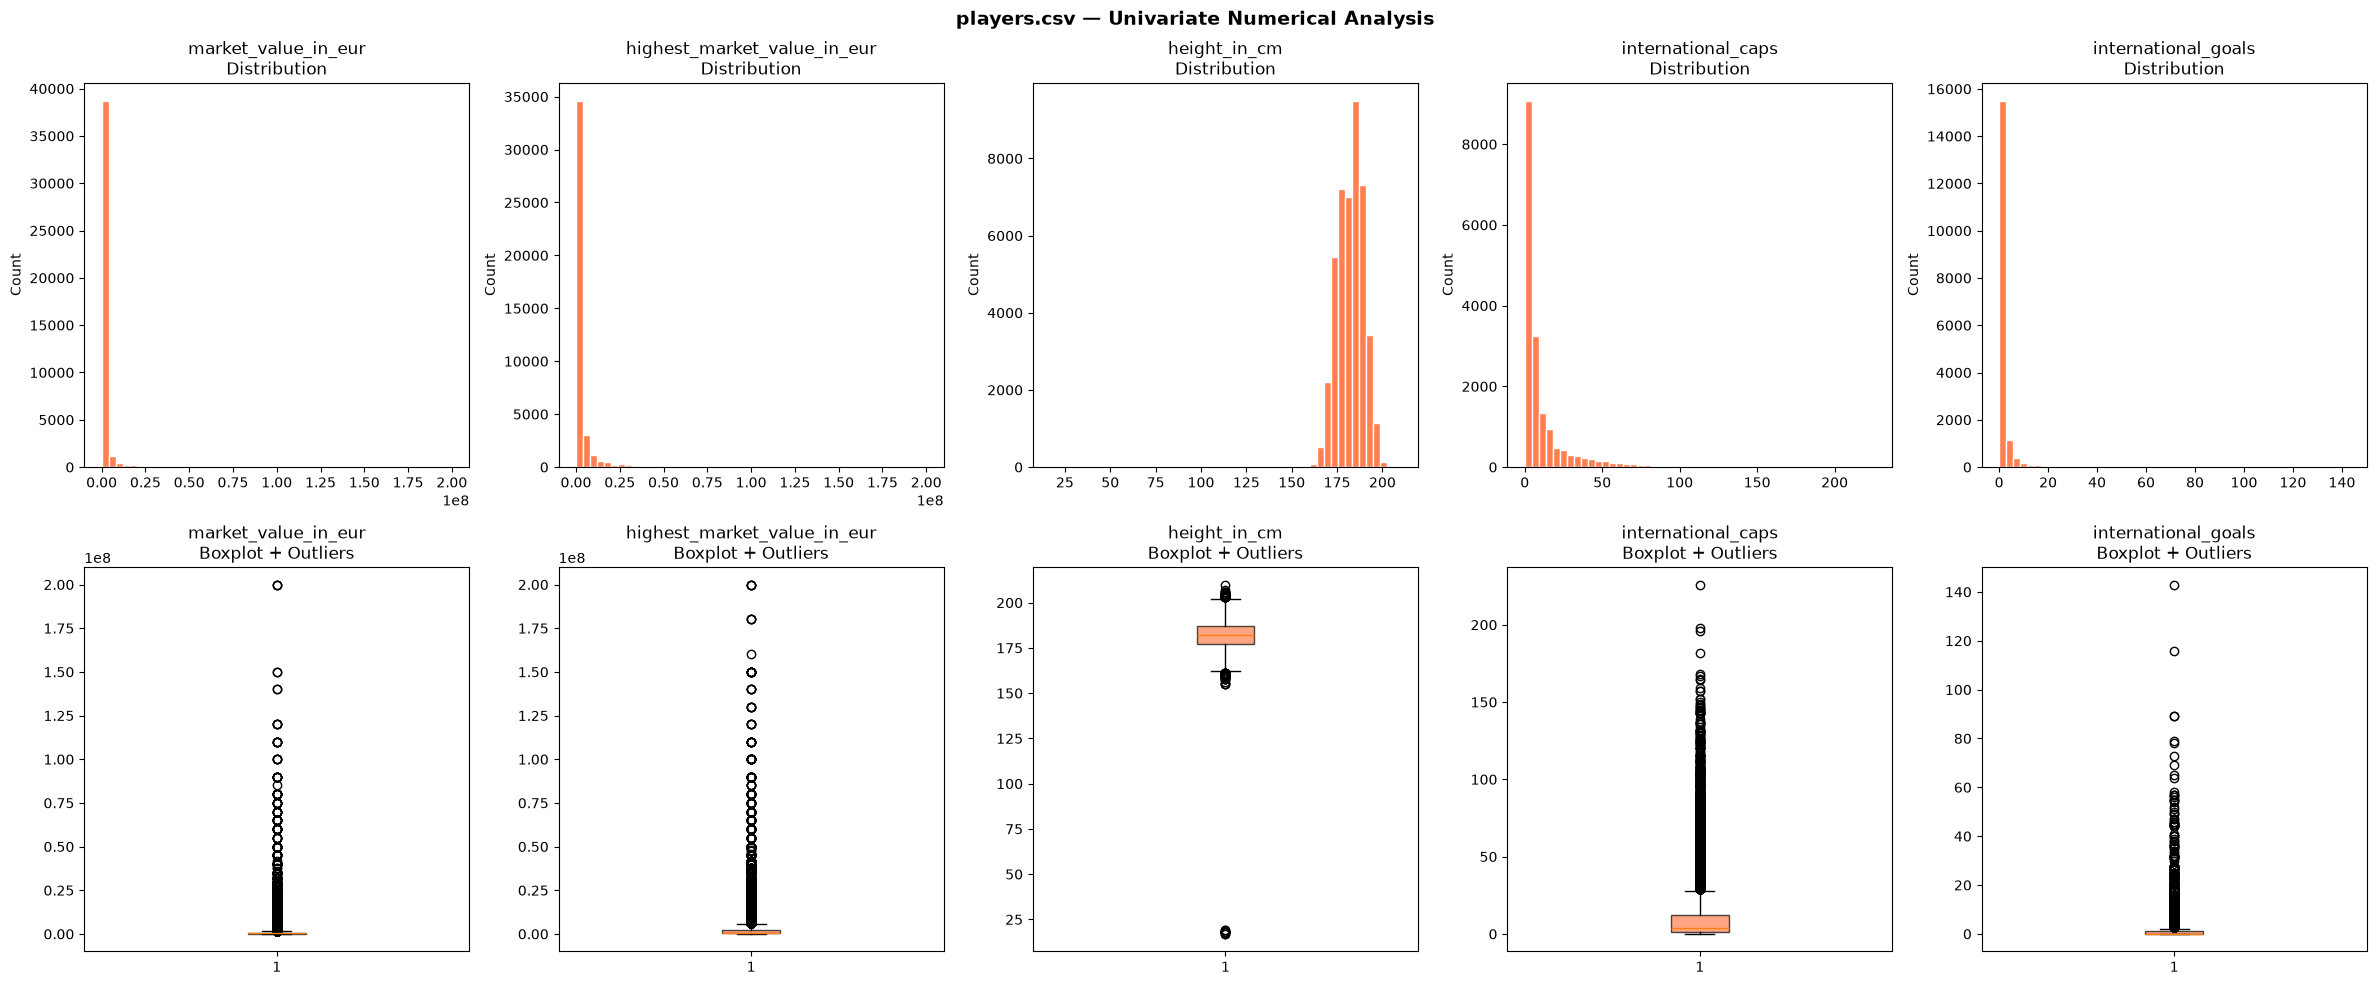

Saved


In [17]:
# players.csv: Univariate Numerical

numerical_players = ['market_value_in_eur', 'highest_market_value_in_eur',
                     'height_in_cm', 'international_caps', 'international_goals']

fig, axes = plt.subplots(2, len(numerical_players), figsize=(24, 10))

for i, col in enumerate(numerical_players):
    data = players[col].dropna()

    # Histogram
    axes[0, i].hist(data, bins=50, color='coral', edgecolor='white')
    axes[0, i].set_title(f'{col}\nDistribution')
    axes[0, i].set_ylabel('Count')

    # Boxplot
    axes[1, i].boxplot(data, patch_artist=True,
                       boxprops=dict(facecolor='coral', alpha=0.7))
    axes[1, i].set_title(f'{col}\nBoxplot + Outliers')

plt.suptitle('players.csv — Univariate Numerical Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '05_players_univariate_numerical.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

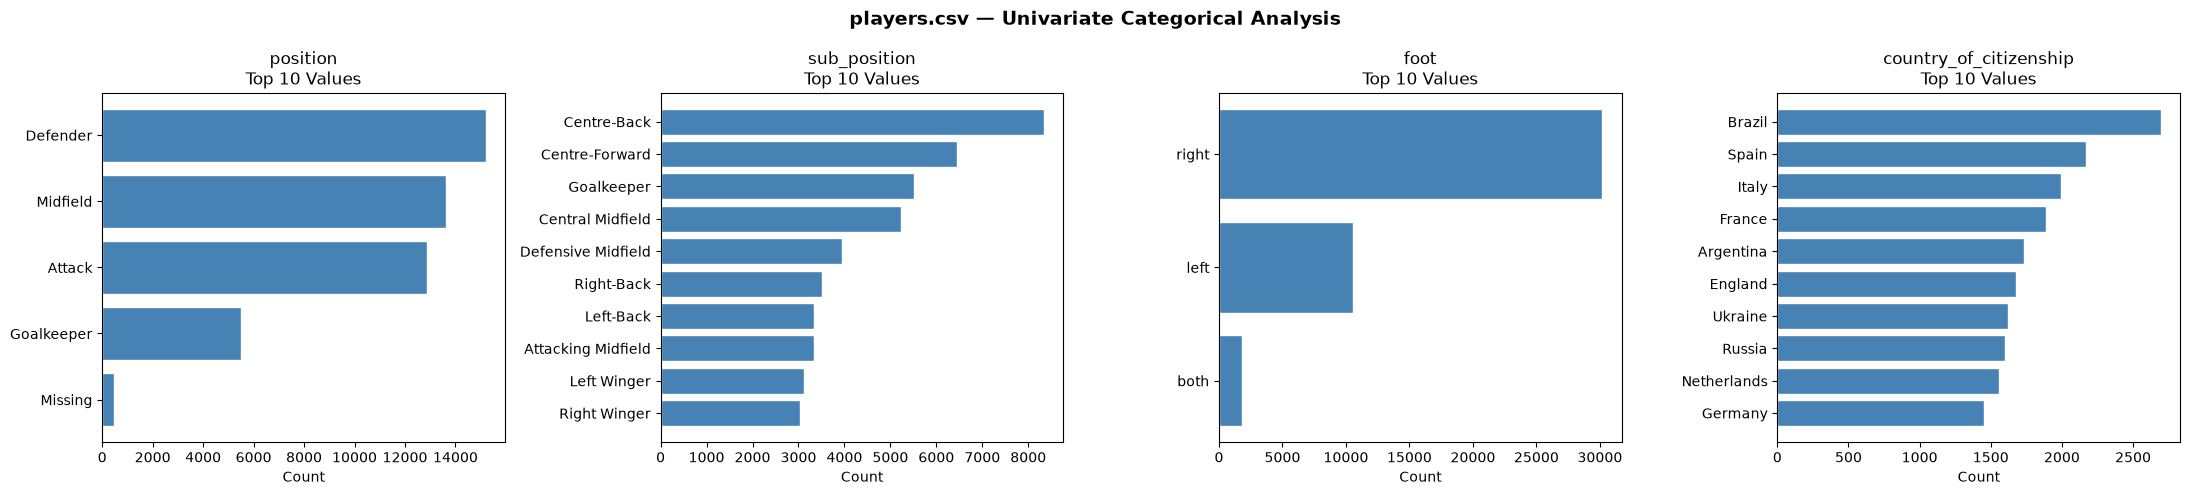

Saved


In [18]:
#  players.csv: Univariate Categorical

categorical_players = ['position', 'sub_position', 'foot', 'country_of_citizenship']

fig, axes = plt.subplots(1, len(categorical_players), figsize=(22, 5))

for i, col in enumerate(categorical_players):
    top10 = players[col].value_counts().head(10)
    axes[i].barh(top10.index, top10.values,
                 color='steelblue', edgecolor='white')
    axes[i].set_title(f'{col}\nTop 10 Values')
    axes[i].set_xlabel('Count')
    axes[i].invert_yaxis()

plt.suptitle('players.csv — Univariate Categorical Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '06_players_univariate_categorical.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

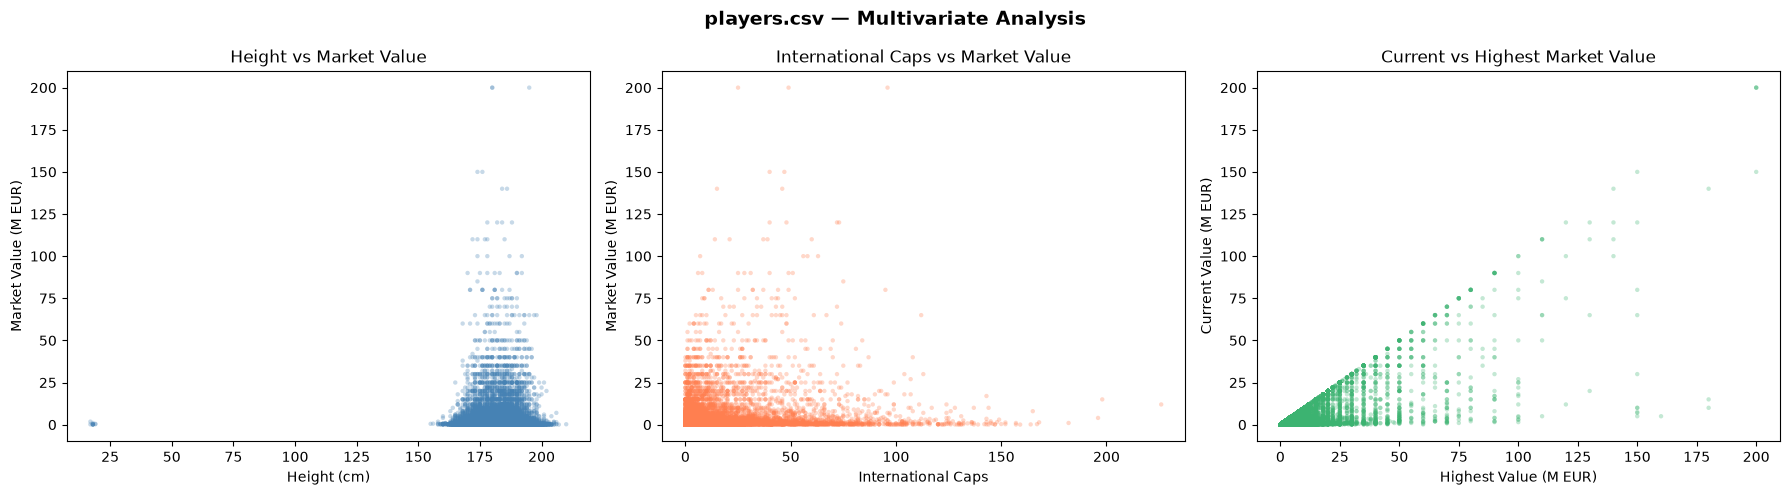

Saved


In [19]:
#  players.csv: Multivariate

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Height vs Market Value
axes[0].scatter(players['height_in_cm'],
                players['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='steelblue', edgecolors='none', s=10)
axes[0].set_title('Height vs Market Value')
axes[0].set_xlabel('Height (cm)')
axes[0].set_ylabel('Market Value (M EUR)')

# International Caps vs Market Value
axes[1].scatter(players['international_caps'],
                players['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='coral', edgecolors='none', s=10)
axes[1].set_title('International Caps vs Market Value')
axes[1].set_xlabel('International Caps')
axes[1].set_ylabel('Market Value (M EUR)')

# Current vs Highest Market Value
axes[2].scatter(players['highest_market_value_in_eur'] / 1_000_000,
                players['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='mediumseagreen', edgecolors='none', s=10)
axes[2].set_title('Current vs Highest Market Value')
axes[2].set_xlabel('Highest Value (M EUR)')
axes[2].set_ylabel('Current Value (M EUR)')

plt.suptitle('players.csv — Multivariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_players_multivariate_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [20]:
#  player_valuations.csv: Basic Info
print("=" * 60)
print("FILE 3: player_valuations.csv")
print("=" * 60)
print(f"Purpose : Historical market value timeline per player")
print(f"Shape   : {player_valuations.shape}")

player_valuations['date'] = pd.to_datetime(player_valuations['date'])
print(f"\nDate range: {player_valuations['date'].min()} → {player_valuations['date'].max()}")
print(f"\nBasic stats:")
print(player_valuations['market_value_in_eur'].describe().round(2))

FILE 3: player_valuations.csv
Purpose : Historical market value timeline per player
Shape   : (640176, 6)

Date range: 2000-01-20 00:00:00 → 2026-05-18 00:00:00

Basic stats:
count    6.401760e+05
mean     2.264433e+06
std      6.650835e+06
min      0.000000e+00
25%      2.000000e+05
50%      5.000000e+05
75%      1.500000e+06
max      2.000000e+08
Name: market_value_in_eur, dtype: float64


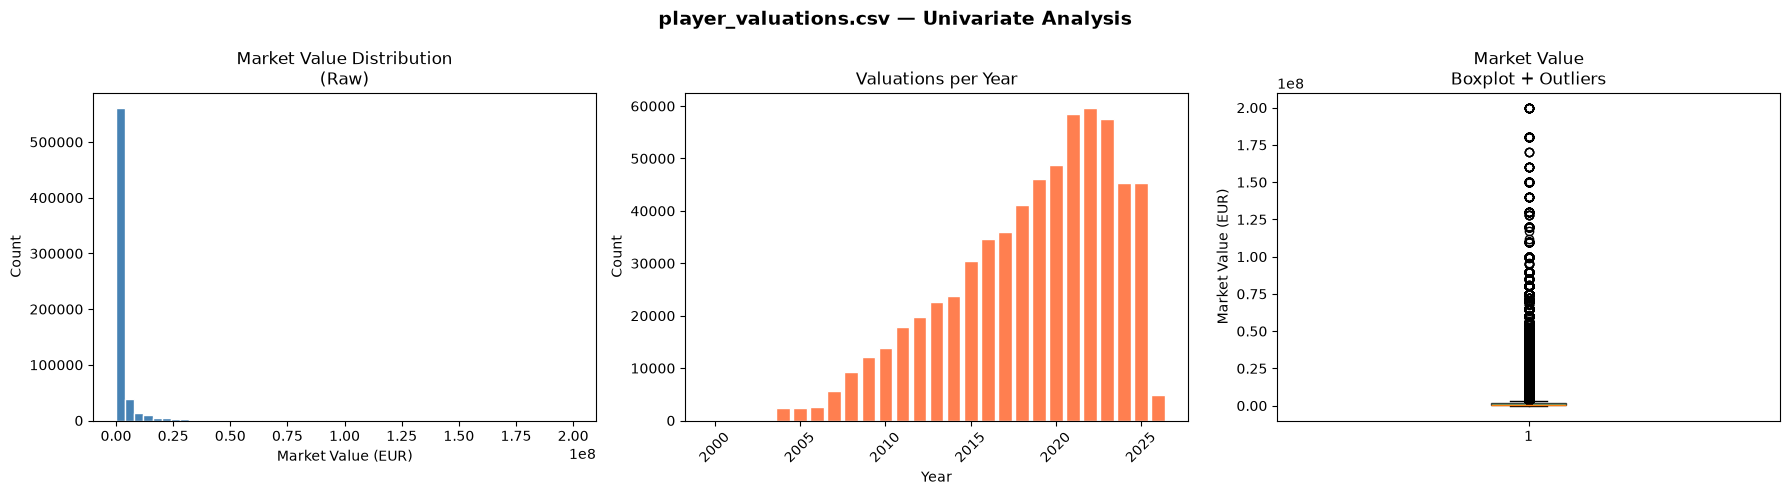

Saved


In [21]:
# player_valuation: Univariate  

player_valuations['date'] = pd.to_datetime(player_valuations['date'])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution RAW (no log)
axes[0].hist(player_valuations['market_value_in_eur'],
             bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Market Value Distribution\n(Raw)')
axes[0].set_xlabel('Market Value (EUR)')
axes[0].set_ylabel('Count')

# Valuations per year
yearly_count = player_valuations.groupby(
    player_valuations['date'].dt.year).size()
axes[1].bar(yearly_count.index, yearly_count.values,
            color='coral', edgecolor='white')
axes[1].set_title('Valuations per Year')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

# Boxplot market value
axes[2].boxplot(player_valuations['market_value_in_eur'].dropna(),
                patch_artist=True,
                boxprops=dict(facecolor='mediumseagreen', alpha=0.7))
axes[2].set_title('Market Value\nBoxplot + Outliers')
axes[2].set_ylabel('Market Value (EUR)')

plt.suptitle('player_valuations.csv — Univariate Analysis',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_player_valuations_univariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

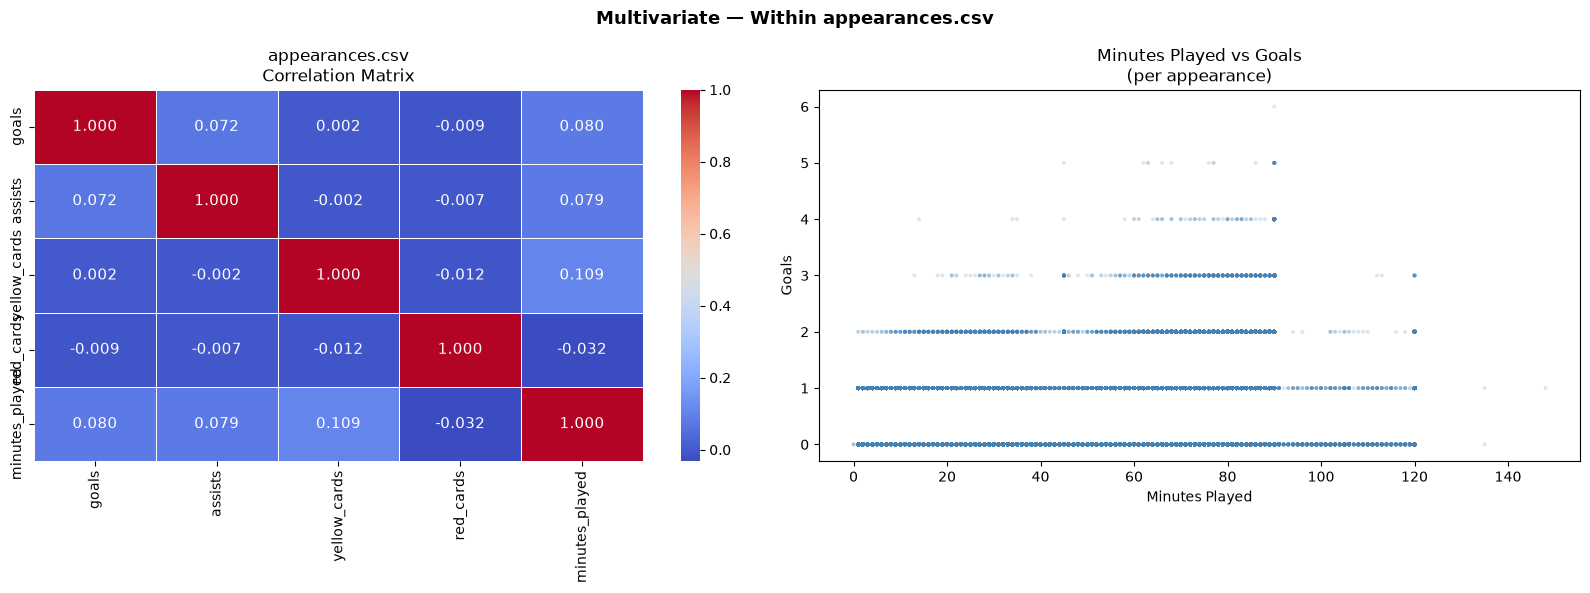

Saved


In [22]:
# Multivariate: Within appearances.csv

numerical_app = ['goals', 'assists', 'yellow_cards',
                 'red_cards', 'minutes_played']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation heatmap
sns.heatmap(appearances[numerical_app].corr(),
            annot=True, fmt='.3f', cmap='coolwarm',
            linewidths=0.5, ax=axes[0], annot_kws={'size': 11})
axes[0].set_title('appearances.csv\nCorrelation Matrix')

# Goals vs Minutes
axes[1].scatter(appearances['minutes_played'], appearances['goals'],
                alpha=0.2, color='steelblue', edgecolors='none', s=8)
axes[1].set_title('Minutes Played vs Goals\n(per appearance)')
axes[1].set_xlabel('Minutes Played')
axes[1].set_ylabel('Goals')

plt.suptitle('Multivariate — Within appearances.csv',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '09_appearances_within_file_multivariate.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

In [23]:
# Multivariate: Cross-file appearances × players
# Aggregate appearances first
player_agg = appearances.groupby('player_id').agg(
    total_goals   = ('goals',          'sum'),
    total_assists = ('assists',        'sum'),
    total_games   = ('game_id',        'count'),
    total_minutes = ('minutes_played', 'sum')
).reset_index()

# Merge với players
merged_check = player_agg.merge(
    players[['player_id', 'market_value_in_eur',
             'international_caps', 'height_in_cm', 'position']],
    on='player_id', how='inner'
).dropna(subset=['market_value_in_eur'])


print(f"Merged for multivariate: {merged_check.shape}")
print(f"\nGoal: Understand how each feature affects market_value_in_eur")

Merged for multivariate: (28028, 9)

Goal: Understand how each feature affects market_value_in_eur


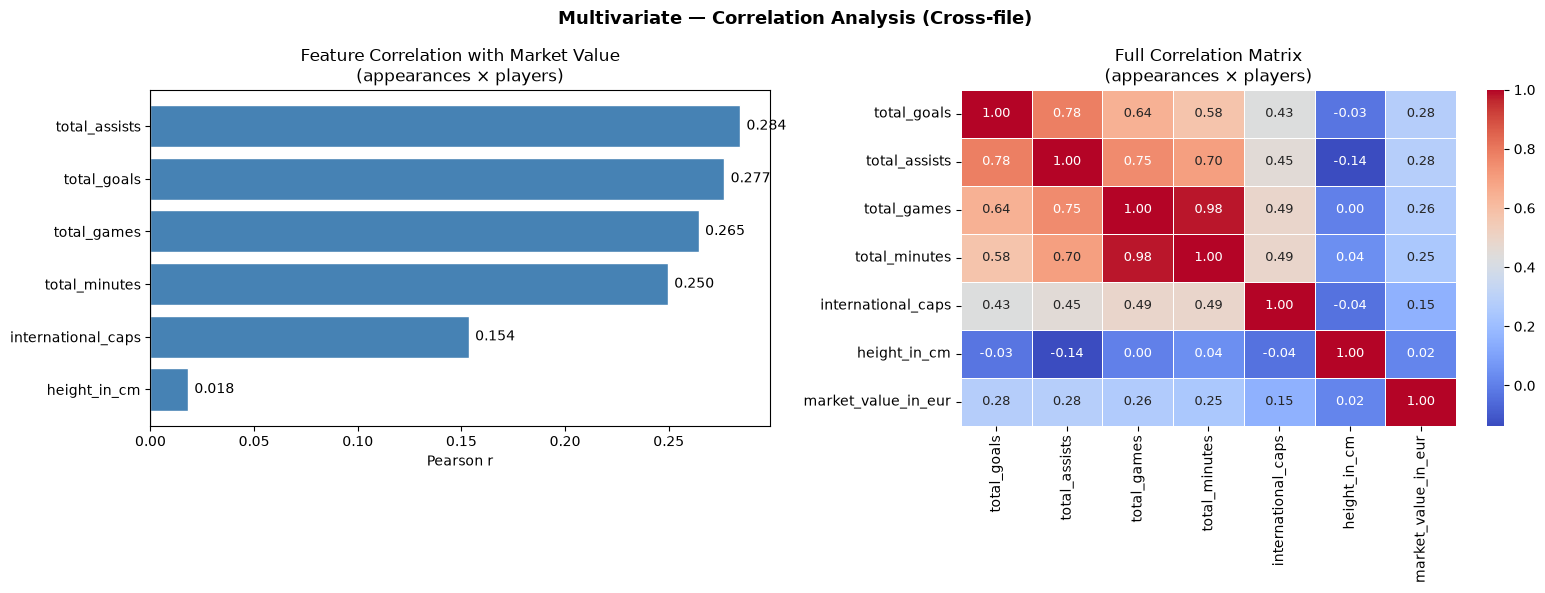

Saved


In [24]:
#  Multivariate: Correlation with Market Value


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation with market value bar chart
corr_value = merged_check[[
    'total_goals', 'total_assists', 'total_games',
    'total_minutes', 'international_caps', 'height_in_cm',
    'market_value_in_eur'
]].corr()['market_value_in_eur'].drop('market_value_in_eur').sort_values()

bar_colors = ['coral' if v < 0 else 'steelblue' for v in corr_value.values]
axes[0].barh(corr_value.index, corr_value.values,
             color=bar_colors, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Feature Correlation with Market Value\n(appearances × players)')
axes[0].set_xlabel('Pearson r')
for i, v in enumerate(corr_value.values):
    axes[0].text(v + 0.003 if v >= 0 else v - 0.003,
                 i, f'{v:.3f}', va='center',
                 ha='left' if v >= 0 else 'right', fontsize=10)

# Heatmap full
corr_full = merged_check[[
    'total_goals', 'total_assists', 'total_games',
    'total_minutes', 'international_caps',
    'height_in_cm', 'market_value_in_eur'
]].corr()
sns.heatmap(corr_full, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5,
            ax=axes[1], annot_kws={'size': 9})
axes[1].set_title('Full Correlation Matrix\n(appearances × players)')

plt.suptitle('Multivariate — Correlation Analysis (Cross-file)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '10_cross_file_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

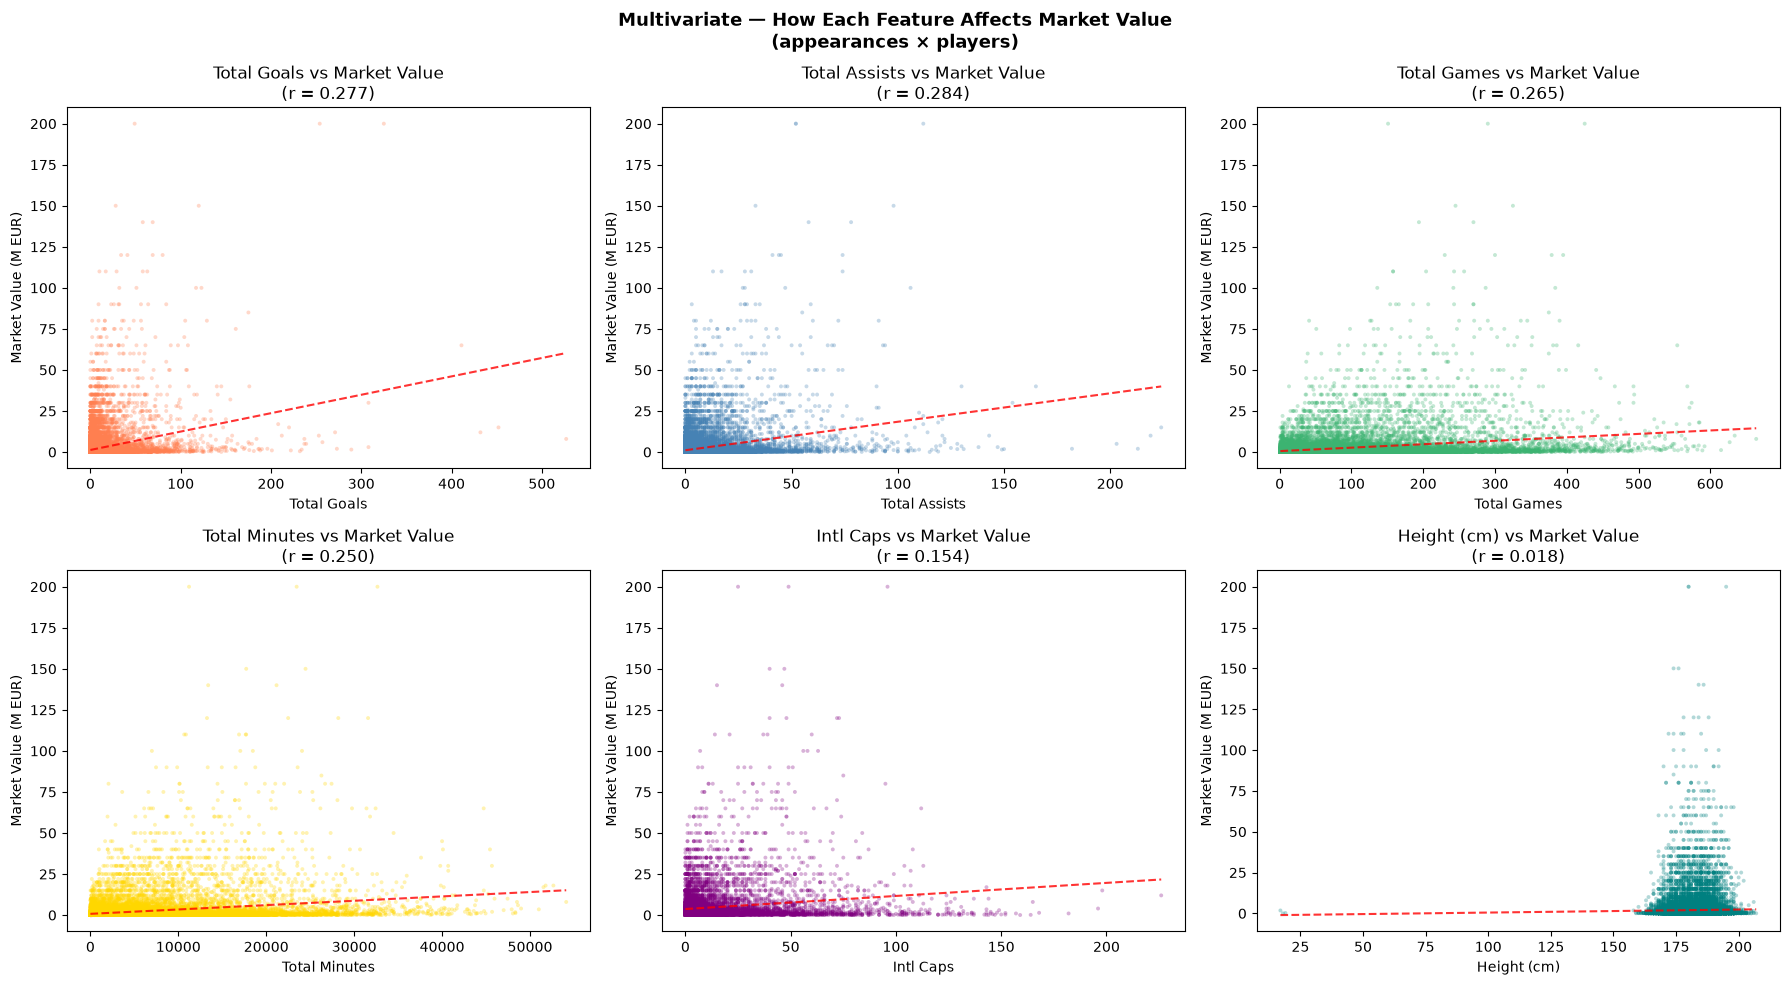

Saved


In [25]:
features = [
    ('total_goals',        'Total Goals',        'coral'),
    ('total_assists',      'Total Assists',      'steelblue'),
    ('total_games',        'Total Games',        'mediumseagreen'),
    ('total_minutes',      'Total Minutes',      'gold'),
    ('international_caps', 'Intl Caps',          'purple'),
    ('height_in_cm',       'Height (cm)',        'teal'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (col, label, color) in zip(axes.flatten(), features):
    data = merged_check.dropna(subset=[col])  # 
    corr = data[col].corr(data['market_value_in_eur'])

    ax.scatter(data[col],
               data['market_value_in_eur'] / 1_000_000,
               alpha=0.3, color=color, edgecolors='none', s=8)

    # Add trend line
    z = np.polyfit(data[col].fillna(0),
                   data['market_value_in_eur'] / 1_000_000, 1)
    p = np.poly1d(z)
    x_line = np.linspace(data[col].min(), data[col].max(), 100)
    ax.plot(x_line, p(x_line), 'r--', linewidth=1.5, alpha=0.8)

    ax.set_title(f'{label} vs Market Value\n(r = {corr:.3f})')
    ax.set_xlabel(label)
    ax.set_ylabel('Market Value (M EUR)')

plt.suptitle('Multivariate — How Each Feature Affects Market Value\n(appearances × players)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '11_features_vs_market_value.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

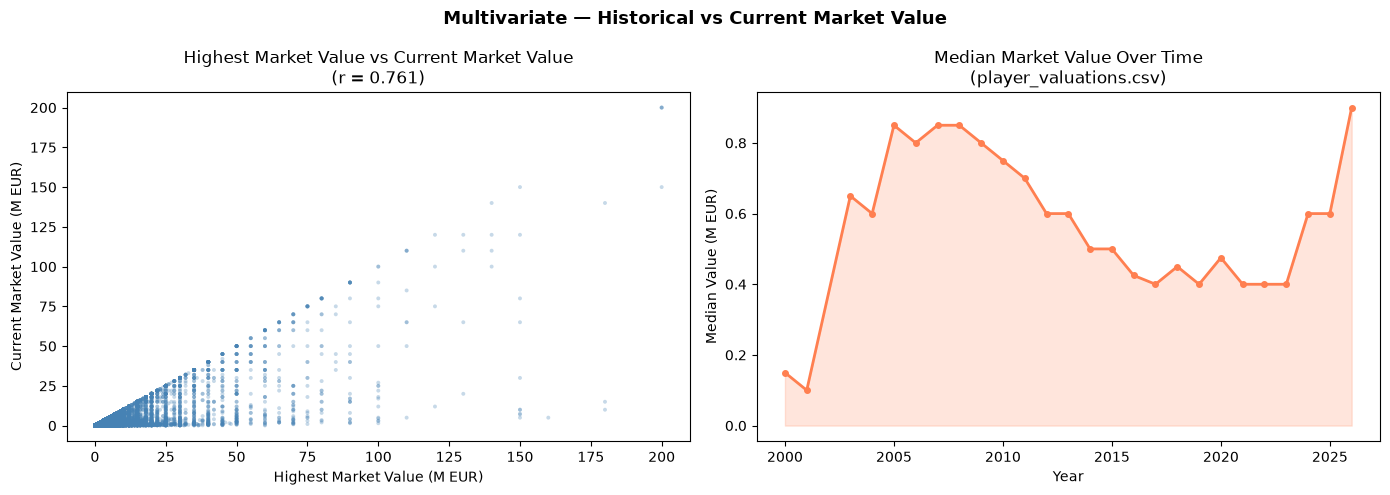

Saved


In [26]:
# Using highest_market_value vs current_market_value
# Bcuz both in players.csv → no duplicate issue

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

data = players[['market_value_in_eur', 
                'highest_market_value_in_eur']].dropna()

# Highest vs Current
corr = data['highest_market_value_in_eur'].corr(
       data['market_value_in_eur'])

axes[0].scatter(data['highest_market_value_in_eur'] / 1_000_000,
                data['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='steelblue', edgecolors='none', s=8)
axes[0].set_title(f'Highest Market Value vs Current Market Value\n(r = {corr:.3f})')
axes[0].set_xlabel('Highest Market Value (M EUR)')
axes[0].set_ylabel('Current Market Value (M EUR)')

# Median historical value over time (from player_valuations)
yearly = player_valuations.groupby(
    pd.to_datetime(player_valuations['date']).dt.year
)['market_value_in_eur'].median()

axes[1].plot(yearly.index, yearly.values / 1_000_000,
             color='coral', linewidth=2, marker='o', markersize=4)
axes[1].fill_between(yearly.index, yearly.values / 1_000_000,
                     alpha=0.2, color='coral')
axes[1].set_title('Median Market Value Over Time\n(player_valuations.csv)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Median Value (M EUR)')
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Multivariate — Historical vs Current Market Value',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '12_historical_vs_current_value.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

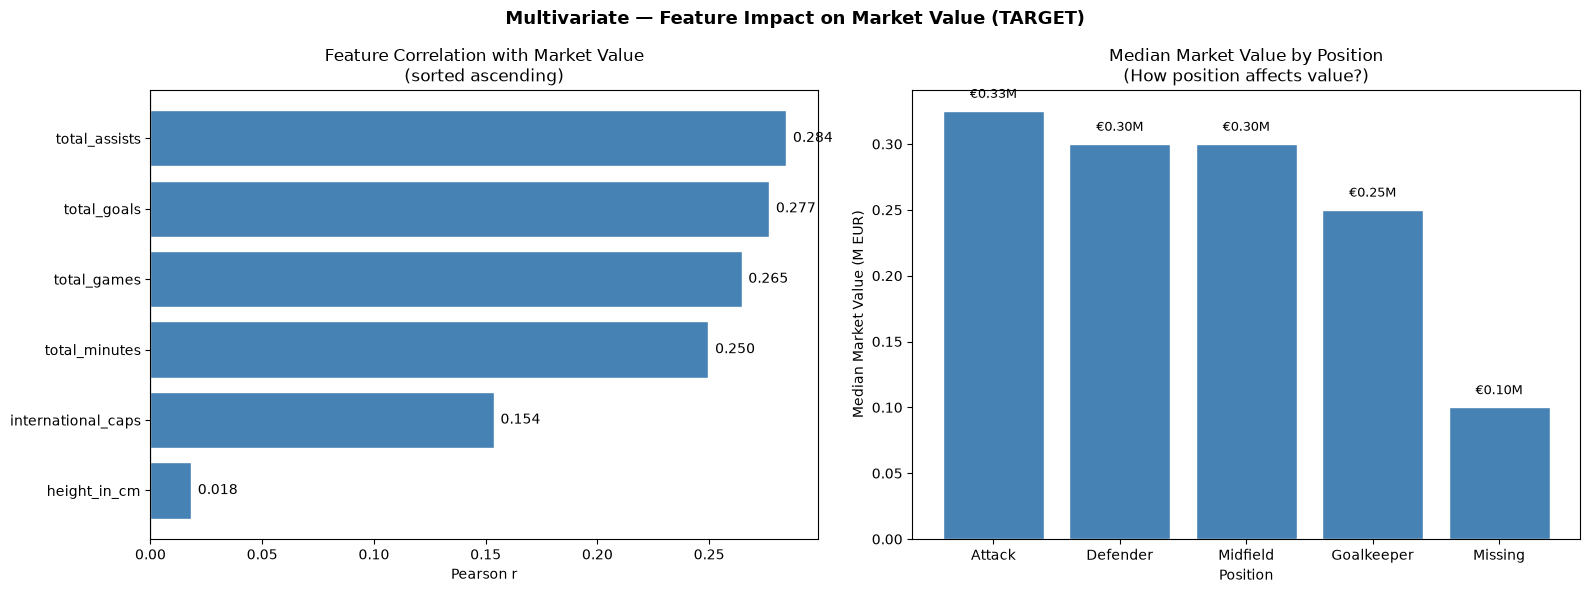

Saved


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation bar chart — sorted
corr_series = merged_check[[
    'total_goals', 'total_assists', 'total_games',
    'total_minutes', 'international_caps', 'height_in_cm',
    'market_value_in_eur'
]].corr()['market_value_in_eur'].drop('market_value_in_eur')\
  .sort_values(ascending=True)

colors = ['coral' if v < 0 else 'steelblue' for v in corr_series.values]
axes[0].barh(corr_series.index, corr_series.values,
             color=colors, edgecolor='white')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('Feature Correlation with Market Value\n(sorted ascending)')
axes[0].set_xlabel('Pearson r')
for i, v in enumerate(corr_series.values):
    axes[0].text(v + 0.003 if v >= 0 else v - 0.003,
                 i, f'{v:.3f}', va='center',
                 ha='left' if v >= 0 else 'right', fontsize=10)

# Market value by position — direct impact
pos_med = merged_check.groupby('position')['market_value_in_eur']\
                .median().sort_values(ascending=False)
axes[1].bar(pos_med.index, pos_med.values / 1_000_000,
            color='steelblue', edgecolor='white')
axes[1].set_title('Median Market Value by Position\n(How position affects value?)')
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Median Market Value (M EUR)')
for i, v in enumerate(pos_med.values / 1_000_000):
    axes[1].text(i, v + 0.01, f'€{v:.2f}M',
                 ha='center', fontsize=9)

plt.suptitle('Multivariate — Feature Impact on Market Value (TARGET)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '13_feature_impact_on_market_value.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")

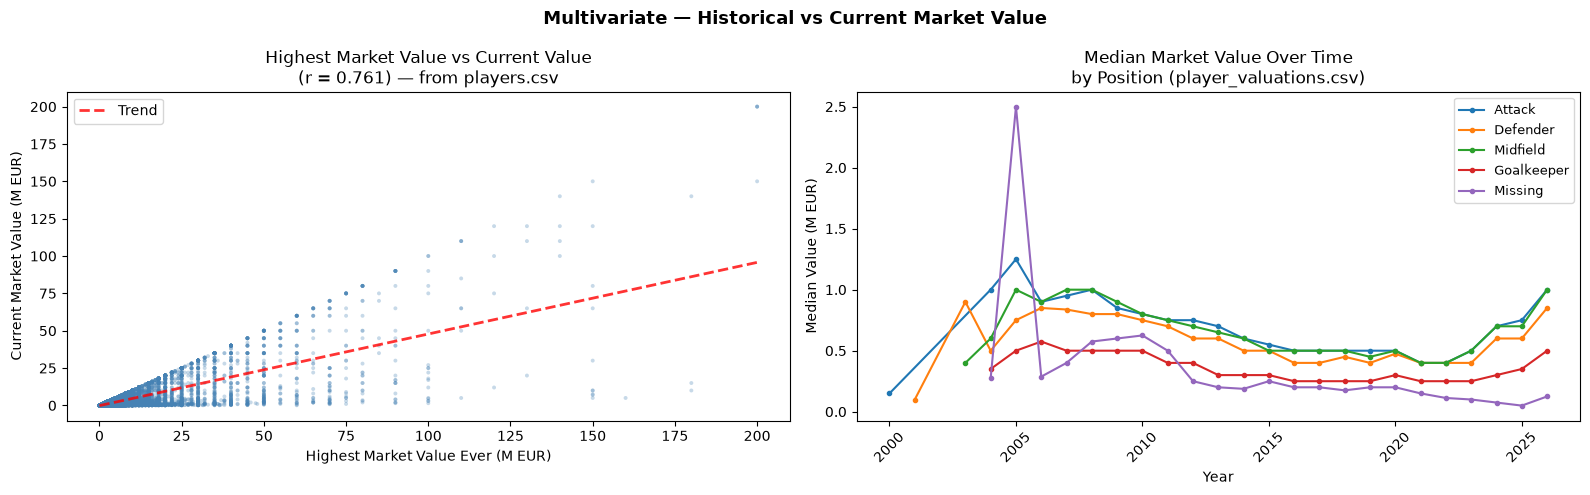

Saved


In [28]:
player_valuations['date'] = pd.to_datetime(player_valuations['date'])


# Chart 1: Highest vs Current Market Value (From players.csv)
# No need merge → No duplicate

data_players = players[['player_id', 'position',
                         'market_value_in_eur',
                         'highest_market_value_in_eur']].dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Highest vs Current
corr = data_players['highest_market_value_in_eur'].corr(
       data_players['market_value_in_eur'])

axes[0].scatter(data_players['highest_market_value_in_eur'] / 1_000_000,
                data_players['market_value_in_eur'] / 1_000_000,
                alpha=0.3, color='steelblue', edgecolors='none', s=8)

# Trend line
z      = np.polyfit(data_players['highest_market_value_in_eur'],
                    data_players['market_value_in_eur'] / 1_000_000, 1)
p      = np.poly1d(z)
x_line = np.linspace(data_players['highest_market_value_in_eur'].min(),
                     data_players['highest_market_value_in_eur'].max(), 100)
axes[0].plot(x_line / 1_000_000, p(x_line),
             'r--', linewidth=2, alpha=0.8, label='Trend')

axes[0].set_title(f'Highest Market Value vs Current Value\n'
                  f'(r = {corr:.3f}) — from players.csv')
axes[0].set_xlabel('Highest Market Value Ever (M EUR)')
axes[0].set_ylabel('Current Market Value (M EUR)')
axes[0].legend()


# Chart 2: Median historical value over time by position
# From player_valuations.csv — No need merge players


# Get position from players → rename to avoid duplicate
pos_lookup = players[['player_id', 'position']].copy()

val_with_pos = player_valuations.merge(
    pos_lookup, on='player_id', how='inner'
)  # No duplicate because player_valuations dont have 'position'

for pos in val_with_pos['position'].dropna().unique():
    pos_data = val_with_pos[val_with_pos['position'] == pos]
    yearly   = pos_data.groupby(
        pos_data['date'].dt.year
    )['market_value_in_eur'].median()
    axes[1].plot(yearly.index, yearly.values / 1_000_000,
                 marker='o', markersize=3, linewidth=1.5, label=pos)

axes[1].set_title('Median Market Value Over Time\nby Position (player_valuations.csv)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Median Value (M EUR)')
axes[1].legend(fontsize=9)
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Multivariate — Historical vs Current Market Value',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '14_historical_vs_current_value_median_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved")   

# Chart 1
# Insights r cao => peak value la good predictor
# Cau thu tung expensive => Van co xu huong expensive
# Justify dung highest_market_value lam feature ML  

# Chart 2
# Attack tang nhanh nhat => Thong thuong thi truong tra nhieu hon cho Attackers
# Goalkeeper tang cham nhat
# => Trend này justify position là important feature

# 2 Chart lien quan the nao den predict market value?
# => C1: highest_market_value -> co the them
        # vao` lam` FEATURE trong ML model
# => C2: Value tang theo YEAR -> thi truong 
        # inflate → justify can normalize data

# Show them phan phoi cua MArket value theo Position 

In [29]:
print("=" * 60)
print("EDA SUMMARY — Group 1: Player Data")
print("=" * 60)
print("""
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ISSUES FOUND (10 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

appearances.csv:
  ⚠️  Issue 1 : goals/assists ~95% zero (sparse)
  ⚠️  Issue 2 : outliers in goals (5+ per game)
  ⚠️  Issue 3 : 2 missing player_name (negligible)

players.csv:
  ❌  Issue 4 : international_caps  63% missing
  ❌  Issue 5 : agent_name          46% missing
  ❌  Issue 6 : contract_expiration 34% missing
  ⚠️  Issue 7 : market_value_in_eur 13% missing
  ⚠️  Issue 8 : foot                10.7% missing
  ⚠️  Issue 9 : height_in_cm        7.7% missing

player_valuations.csv:
  ⚠️  Issue 10: competition_id      14% missing

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
INSIGHTS (5 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ✅ Insight 1: international_caps strongest
               predictor of market value
  ✅ Insight 2: Consistency (games/minutes)
               correlates more than raw stats
  ✅ Insight 3: Goals/assists weaker than expected
  ✅ Insight 4: Market value heavily right-skewed
  ✅ Insight 5: Market value inflating over time

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
PREPROCESSING PLAN
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  Issue 1  → Aggregate to player level
  Issue 2  → Keep (model handles outliers)
  Issue 3  → Ignore (negligible)
  Issue 4  → Fill 0 (NaN = never called up)
  Issue 5  → DROP column
  Issue 6  → DROP column
  Issue 7  → DROP rows (cannot impute TARGET)
  Issue 8  → Fill 'Unknown'
  Issue 9  → Fill median
  Issue 10 → Ignore (not needed for model)

  Additional steps:
  → Merge appearances + players on player_id
  → Encode: position, sub_position
  → Normalize: StandardScaler
  → Log transform: market_value (for ML only)
""")

pd.DataFrame({
    'ID'         : [f'Issue {i}' for i in range(1,11)] +
                   [f'Insight {i}' for i in range(1,6)],
    'Category'   : ['Issue']*10 + ['Insight']*5,
    'Description': [
        'goals/assists ~95% zero',
        'Outliers in goals per game',
        '2 missing player_name',
        'international_caps 63% missing',
        'agent_name 46% missing',
        'contract_expiration 34% missing',
        'market_value 13% missing (TARGET)',
        'foot 10.7% missing',
        'height_in_cm 7.7% missing',
        'competition_id 14% missing',
        'international_caps strongest predictor',
        'Consistency > raw stats',
        'Goals/assists weaker than expected',
        'Market value right-skewed',
        'Market value inflating over time'
    ],
    'Action'     : [
        'Aggregate by player_id',
        'Keep — model handles',
        'Ignore',
        'Fill with 0',
        'Drop column',
        'Drop column',
        'Drop rows',
        "Fill 'Unknown'",
        'Fill median',
        'Ignore',
        'Keep as top feature',
        'Include total_games, total_minutes',
        'Still include all stats',
        'Log transform for ML',
        'Consider year feature in future'
    ]
}).to_csv('../../results/tables/eda_summary_group1.csv', index=False)

print("✅ Saved eda_summary_group1.csv")

EDA SUMMARY — Group 1: Player Data

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
ISSUES FOUND (10 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

appearances.csv:
  ⚠️  Issue 1 : goals/assists ~95% zero (sparse)
  ⚠️  Issue 2 : outliers in goals (5+ per game)
  ⚠️  Issue 3 : 2 missing player_name (negligible)

players.csv:
  ❌  Issue 4 : international_caps  63% missing
  ❌  Issue 5 : agent_name          46% missing
  ❌  Issue 6 : contract_expiration 34% missing
  ⚠️  Issue 7 : market_value_in_eur 13% missing
  ⚠️  Issue 8 : foot                10.7% missing
  ⚠️  Issue 9 : height_in_cm        7.7% missing

player_valuations.csv:
  ⚠️  Issue 10: competition_id      14% missing

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
INSIGHTS (5 total)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

  ✅ Insight 1: international_caps strongest
               predictor of market value
  ✅ Insight 2: Consistency (games/minutes)
               correlates more than raw stats
  ✅ Insight 3: Goals/assists weak